#**Taller 6: Funciones, Variables Globales y Locales y Módulos**
Juan Manuel Rosero García

In [138]:
#@title Comprueba gfortran (y lo instala en Colab si falta) y crea la carpeta del Taller
!which gfortran > /dev/null || (apt-get -qq update && apt-get -qq install -y gfortran > /dev/null)
!gfortran --version | head -1
!mkdir -p taller_nucleo_atomico

GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


##**Parte B: Programa de Fortran**

###**Pseudocódigo Marco**
```
MÓDULO del modelo
    constantes: a_V, a_S, a_C, a_A, M_n, M_H
    funciones de los cuatro términos               (entradas: Z y/o A; salida: el término [MeV])
    función E_B(Z, A)                              (usa las cuatro funciones anteriores)
    función M(Z, A)                                (usa E_B)
    procedimiento Z_estable                        (entrada: A; resultados: el Z de máximo enlace y su E_B)
        
        Inicializar una variable para guardar la energía mínima de enlace con un valor muy grande (m_Eb=1.0e33_dp) y otra para el Z de menor E_B. Mediante un ciclo sobre todo los valores desde Z = 1 hasta Z = A, evaluamos E_B y si es menor que m_Eb, actualizamos m_Eb por ese valor de E_B y registramos el valor de Z.

        Se usa una subrutina porque es necesario devolver 2 valores distintos (Z de máximo enlace y su respectiva energía E_B), mientras que una función en fortran solo devuelve un único valor.

PROGRAMA PRINCIPAL (usa el módulo)
    para cada uno de los 8 núcleos, en el orden del enunciado:
        escribir una fila de nucleos.dat: Z, A, los cuatro términos, E_B y M
    para A = 4, 5, ..., 260:
        obtener el Z de máximo enlace y su E_B con Z_estable
        escribir una fila de valle.dat: A, Z, E_B

        Inicializar una variable global con un valor elevado, para el mínimo enlace global antes de iniciar el ciclo sobre A. En cada iteración, se compara el E_B obtenido para el núcleo más ligado de ese A con el mínimo global, si es menor se actualiza el valor mínimo y guardar A y Z. Al finalizar, este registro contendrá el núcleo más ligado.

    escribir el núcleo más ligado en maximo.dat
```

###**Desarrollo del Módulo (`modulo_nucleo.f90`)**

In [139]:
%%writefile taller_nucleo_atomico/modulo_nucleo.f90
! Taller 6 -- Módulo de la fórmula semiempírica
module modulo_nucleo
  implicit none
  integer, parameter :: dp = kind(1.0d0)

  !Constantes :D
  real(dp), parameter :: a_V = 15.8_dp  !Coeficiente de Volumen [MeV]
  real(dp), parameter :: a_S = 18.3_dp  !Coeficiente de superficie [MeV]
  real(dp), parameter :: a_C = 0.71_dp  !Coeficiente de Coulomb [MeV]
  real(dp), parameter :: a_A = 92.7_dp  !Coeficiente de Asimetría [MeV]
  real(dp), parameter :: M_n = 939.57_dp  !Masa del Neutrón [MeV]
  real(dp), parameter :: M_H = 938.78_dp  !Masa del Hidrógeno [MeV]

contains
  !Término de volumen (-a_V)
  real(dp) function termino_volumen()
    termino_volumen = -a_V
  end function termino_volumen

  !Término de superficie (a_S * A^(-1/3))
  real(dp) function termino_superficie(A)
    real(dp), intent(in) :: A
    termino_superficie = a_S * A**(-1.0_dp/3.0_dp)
  end function termino_superficie

  !Término de Coulomb (a_C * Z^2 * A^(-4/3))
  real(dp) function termino_coulomb(Z, A)
    real(dp), intent(in) :: Z, A
    termino_coulomb = a_C * Z**2 * A**(-4.0_dp/3.0_dp)
  end function termino_coulomb

  !Término de asimetría (a_A * (Z - A/2)^2 / A^2)
  real(dp) function termino_asimetria(Z, A)
    real(dp), intent(in) :: Z, A
    termino_asimetria = a_A * (Z - 0.5_dp*A)**2 / A**2
  end function termino_asimetria

  !Energía de enlace por nucleón (suma de los cuatro términos)
  real(dp) function energia_enlace(Z, A)
    real(dp), intent(in) :: Z, A
    real(dp) :: rZ, rA
    rZ = Z
    rA = A
    energia_enlace = termino_volumen() + termino_superficie(rA) + termino_coulomb(rZ, rA) + termino_asimetria(rZ, rA)
  end function energia_enlace

  !Masa atómica M(Z, A)
  real(dp) function masa_atomica(Z, A)
    real(dp), intent(in) :: Z, A
    real(dp) :: rZ, rA
    rZ = Z
    rA = A
    masa_atomica = rZ * M_H + (rA - rZ) * M_n + rA * energia_enlace(rZ, rA)
  end function masa_atomica

  !Subrutina que encuentra el Z de máximo enlace para un A dado
  subroutine Z_estable(A_int, z_optimo, m_Eb)
    integer, intent(in) :: A_int
    integer, intent(out) :: z_optimo
    real(dp), intent(out) :: m_Eb

    integer :: z
    real(dp) :: rA, eb_actual

    rA = real(A_int, dp)
    m_Eb = 1.0e33_dp
    z_optimo = 1

    do z = 1, A_int
       eb_actual = energia_enlace(real(z, dp), rA)
       if (eb_actual < m_Eb) then
          m_Eb = eb_actual
          z_optimo = z
       end if
    end do
  end subroutine Z_estable

end module modulo_nucleo

Overwriting taller_nucleo_atomico/modulo_nucleo.f90


### **Programa Principal (`programa_nucleo.f90`)**

In [140]:
%%writefile taller_nucleo_atomico/programa_nucleo.f90
! Taller 6 -- Programa principal
program programa_nucleo
  use modulo_nucleo, only: dp, energia_enlace, masa_atomica, Z_estable, &
                           termino_volumen, termino_superficie, &
                           termino_coulomb, termino_asimetria

  implicit none

  integer :: u_nucleos, u_valle, u_maximo
  integer :: A, Z
  real(dp) :: eb
  real(dp) :: min_eb_global
  integer :: A_max_global, Z_max_global

  !--- 1. Los ocho nucleos, en el orden del enunciado---
  open(newunit=u_nucleos, file='nucleos.dat', status='replace')

  call escribir_nucleo(u_nucleos, 94, 244)  !Plutonio-244
  call escribir_nucleo(u_nucleos, 32,  70)  !Germanio-70
  call escribir_nucleo(u_nucleos, 72, 179)  !Hafnio-179
  call escribir_nucleo(u_nucleos, 18,  38)  !Argón-38
  call escribir_nucleo(u_nucleos, 26,  56)  !Hierro-56
  call escribir_nucleo(u_nucleos, 20,  40)  !Calcio-40
  call escribir_nucleo(u_nucleos, 92, 235)  !Uranio-235
  call escribir_nucleo(u_nucleos, 92, 238)  !Uranio-238

  close(u_nucleos)

  !---2. Para cada A, encontrar el Z de menor EB (mayor B/A)---
  open(newunit=u_valle, file='valle.dat', status='replace', action='write')

  min_eb_global = huge(1.0_dp)  ! inicializar antes del ciclo con el mayor número posible
  A_max_global = 0
  Z_max_global = 0

  do A = 4, 260
     call Z_estable(A, Z, eb)   ! Usamos 'eb' correctamente
     write(u_valle, '(2(i5,1x),f20.10)') A, Z, eb

     ! Identificar el núcleo más ligado de toda la curva
     if (eb < min_eb_global) then
        min_eb_global = eb
        A_max_global = A
        Z_max_global = Z
     end if
  end do
  close(u_valle)

  !--- 3. Registrar el maximo global con el mismo orden A, Z, EB---
  open(newunit=u_maximo, file='maximo.dat', status='replace', action='write')
  write(u_maximo, '(2(i5,1x),f20.10)') A_max_global, Z_max_global, min_eb_global
  close(u_maximo)

  print '(a)', 'Taller 6: archivos nucleos.dat, valle.dat y maximo.dat creados.'

contains

  !Escribe: entrada unidad, Z_val, A_val; salida de los términos y propiedades
  subroutine escribir_nucleo(unidad, Z_val, A_val)
    integer, intent(in) :: unidad, Z_val, A_val
    real(dp) :: rZ, rA
    real(dp) :: e_vol, e_sup, e_coul, e_asim, eb_nuc, m

    rZ = real(Z_val, dp)
    rA = real(A_val, dp)

    e_vol  = termino_volumen()
    e_sup  = termino_superficie(rA)
    e_coul = termino_coulomb(rZ, rA)
    e_asim = termino_asimetria(rZ, rA)
    eb_nuc = energia_enlace(rZ, rA)
    m      = masa_atomica(rZ, rA)

    write(unidad, '(2(i5,1x),6(f20.10,1x))') Z_val, A_val, e_vol, e_sup, e_coul, e_asim, eb_nuc, m
  end subroutine escribir_nucleo

end program programa_nucleo

Overwriting taller_nucleo_atomico/programa_nucleo.f90


In [141]:
# Compilación y ejecución (NO MODIFICAR): primero el módulo, después el programa.
# Se ejecuta dentro de taller_nucleo_atomico/ para que los .dat queden allí.
!cd taller_nucleo_atomico && gfortran -Wall -Wextra modulo_nucleo.f90 programa_nucleo.f90 -o nucleo && ./nucleo

Taller 6: archivos nucleos.dat, valle.dat y maximo.dat creados.


##**Analisis y Visualización con Python**

In [142]:
%%writefile taller_nucleo_atomico/analisis_nucleo.py
"""Taller 6 - Analisis de la energia nuclear en Python.

Solo se analizan las tablas creadas por Fortran; no se repite el modelo.
"""

import numpy as np
import matplotlib.pyplot as plt


def leer_valle(archivo):
    """Entrada: ruta de valle.dat. Salida: tres columnas A, Z, EB (arrays)."""
    datos = np.loadtxt(archivo)
    if datos.ndim != 2 or datos.shape[1] != 3:
        raise ValueError("valle.dat debe tener tres columnas: A, Z, EB")
    return datos[:, 0], datos[:, 1], datos[:, 2]


def buscar_maximo(a, z, eb):
    """Entradas: columnas A, Z, EB. Salida: (A, Z, EB) del menor EB.

    Recorre cada fila con ciclo y condicional, sin min ni argmin.
    """
    if len(eb) == 0 or len(a) != len(eb) or len(z) != len(eb):
        raise ValueError("Las tres columnas deben tener la misma longitud no vacia")
    a_mejor = int(a[0])
    z_mejor = int(z[0])
    eb_mejor = float(eb[0])
    for i in range(1, len(eb)):
        if float(eb[i]) < eb_mejor:
            a_mejor = int(a[i])
            z_mejor = int(z[i])
            eb_mejor = float(eb[i])
    return a_mejor, z_mejor, eb_mejor


def guardar_maximo(archivo, a, z, eb):
    """Entradas: ruta, A, Z, EB. Salida: maximo_python.dat (A Z EB)."""
    with open(archivo, "w", encoding="utf-8") as salida:
        salida.write(f"{int(a):5d} {int(z):5d} {float(eb):20.10f}\n")


def graficar_curva(a, z, eb, experimentales, archivo):
    """Entradas: columnas del valle, datos experimentales y ruta PNG.

    Salida: grafica B/A=-EB vs. A del modelo y diez puntos experimentales,
    guardando la imagen y mostrándola en pantalla.
    """
    a_exp = [dato[2] for dato in experimentales]
    b_exp = [dato[3] for dato in experimentales]

    fig, ax = plt.subplots(figsize=(9, 5.2))
    # Se usa -eb para corregir la orientación del modelo de Fortran y mostrar el pico hacia arriba
    ax.plot(a, -eb, linewidth=2.1, label="Modelo: máximo enlace por A")
    ax.scatter(a_exp, b_exp, s=45, marker="o", zorder=3, label="Núclidos medidos")

    offsets = {"He-4": (4, 8), "Fe-56": (-28, 10), "Ni-62": (8, -13),
               "Pb-208": (-26, 9), "U-238": (4, -12)}
    for nombre, _, masa_a, energia in experimentales:
        if nombre in offsets:
            ax.annotate(nombre, (masa_a, energia), xytext=offsets[nombre],
                        textcoords="offset points", fontsize=8)

    ax.set_xlabel("Número de nucleones A")
    ax.set_ylabel("Energía de enlace por nucleón B/A [MeV]")
    ax.set_title("Taller 6: fórmula semiempírica de masa nuclear")
    ax.grid(alpha=0.22)
    ax.legend(loc="lower right")
    ax.set_xlim(0, 265)
    fig.tight_layout()

    # Guarda la imagen requerida y además la muestra en el Colab
    fig.savefig(archivo, dpi=190)
    plt.show()
    plt.close(fig)

Overwriting taller_nucleo_atomico/analisis_nucleo.py


###**Programa Principal Usando el módulo**

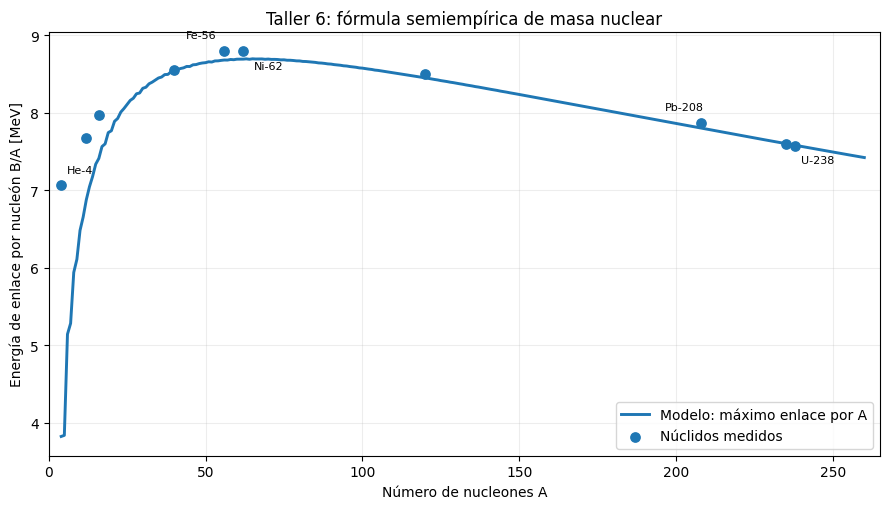

Maximo en Python: A=65, Z=29, EB=-8.6950690577 MeV/nucleons
Archivos generados: maximo_python.dat y curva_enlace.png


In [143]:
# C.4 -- Uso del módulo de análisis
# Las tres líneas siguientes ya están escritas: agregan la carpeta del Taller a la
# ruta de búsqueda de Python, importan el módulo y lo releen si fue modificado.
import sys, importlib
sys.path.insert(0, "taller_nucleo_atomico")
import analisis_nucleo
_ = importlib.reload(analisis_nucleo)

# Definición de los datos experimentales requeridos
EXPERIMENTALES = [
    ("He-4",    2,   4, 7.0739),
    ("C-12",    6,  12, 7.6801),
    ("O-16",    8,  16, 7.9762),
    ("Ca-40",  20,  40, 8.5513),
    ("Fe-56",  26,  56, 8.7903),
    ("Ni-62",  28,  62, 8.7945),
    ("Sn-120", 50, 120, 8.5045),
    ("Pb-208", 82, 208, 7.8675),
    ("U-235",  92, 235, 7.5909),
    ("U-238",  92, 238, 7.5701)
]

# Ejecución del análisis
a, z, eb = analisis_nucleo.leer_valle("taller_nucleo_atomico/valle.dat")
a_mejor, z_mejor, eb_mejor = analisis_nucleo.buscar_maximo(a, z, eb)
analisis_nucleo.guardar_maximo("taller_nucleo_atomico/maximo_python.dat", a_mejor, z_mejor, eb_mejor)
analisis_nucleo.graficar_curva(a, z, eb, EXPERIMENTALES, "taller_nucleo_atomico/curva_enlace.png")

print(f"Maximo en Python: A={a_mejor}, Z={z_mejor}, EB={eb_mejor:.10f} MeV/nucleons")
print("Archivos generados: maximo_python.dat y curva_enlace.png")

In [144]:
#@title Celda de Verificación
# ===================== VERIFICACIÓN — NO MODIFICAR =====================
from pathlib import Path
import numpy as np

CARPETA = Path("taller_nucleo_atomico")
veredictos = []

def informar(nombre, condicion, detalle=""):
    veredictos.append(bool(condicion))
    print(f"{'PASS' if condicion else 'FAIL'} | {nombre}" + (f" — {detalle}" if detalle else ""))

def leer_salida(nombre, filas, columnas, origen="fortran"):
    ruta = CARPETA / nombre
    if not ruta.is_file():
        raise ValueError(f"falta {ruta}")
    if origen == "fortran":
        fuentes = [CARPETA / "modulo_nucleo.f90", CARPETA / "programa_nucleo.f90"]
    else:
        fuentes = [CARPETA / "analisis_nucleo.py", CARPETA / "valle.dat"]
    for fuente in fuentes:
        if not fuente.is_file():
            raise ValueError(f"falta {fuente}")
        if ruta.stat().st_mtime < fuente.stat().st_mtime:
            raise ValueError(f"{nombre} es anterior a {fuente.name}: vuelva a ejecutar el cálculo correspondiente")
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape != (filas, columnas) or not np.isfinite(datos).all():
        raise ValueError(f"formato incorrecto en {nombre}: se esperaban {filas} filas y {columnas} columnas finitas")
    return datos

# Implementación de referencia exclusiva de la verificación.
def referencia_terminos(z, a):
    z, a = np.asarray(z, dtype=float), np.asarray(a, dtype=float)
    return np.broadcast_arrays(-15.8 + np.zeros_like(a), 18.3*a**(-1.0/3.0),
                               0.71*z**2*a**(-4.0/3.0), 92.7*(z-a/2.0)**2/a**2)

def referencia_enlace(z, a):
    return sum(referencia_terminos(z, a))

def leer_valle():
    datos = leer_salida("valle.dat", 257, 3)
    if not np.array_equal(datos[:, 0], np.arange(4, 261)):
        raise ValueError("valle.dat debe tener A = 4, 5, ..., 260, en ese orden")
    if not np.array_equal(datos[:, 1], np.rint(datos[:, 1])):
        raise ValueError("los valores de Z deben ser enteros")
    if np.any((datos[:, 1] < 1) | (datos[:, 1] > datos[:, 0])):
        raise ValueError("cada fila debe cumplir 1 <= Z <= A")
    return datos

# 1) Ocho núclidos: todos los términos, el enlace y la masa.
try:
    nuc = leer_salida("nucleos.dat", 8, 8)
    orden = np.array([(94,244), (32,70), (72,179), (18,38), (26,56), (20,40), (92,235), (92,238)])
    if not np.array_equal(nuc[:, :2], orden):
        raise ValueError("Z y A deben ser enteros y seguir el orden del enunciado")
    z, a = orden[:, 0], orden[:, 1]
    terminos = np.column_stack(referencia_terminos(z, a))
    eb = terminos.sum(axis=1)
    masa = z*938.78 + (a-z)*939.57 + a*eb
    ok = (np.allclose(nuc[:, 2:6], terminos, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 6], eb, rtol=0, atol=1e-7)
          and np.allclose(nuc[:, 7], masa, rtol=0, atol=1e-3)
          and np.allclose(nuc[:, 2:6].sum(axis=1), nuc[:, 6], rtol=0, atol=1e-7))
    informar("Caso 1: ocho núclidos", ok, f"Pu-244: E_B = {nuc[0,6]:.8f} MeV; M = {nuc[0,7]:.4f} MeV")
except Exception as error:
    informar("Caso 1: ocho núclidos", False, str(error))

# 2) La búsqueda obtiene el máximo enlace para cada A del intervalo.
try:
    valle = leer_valle()
    correctos = []
    for a, z, eb in valle:
        candidatos = np.arange(1, int(a)+1)
        energias = referencia_enlace(candidatos, a)
        correctos.append(abs(float(referencia_enlace(z, a)) - energias.min()) <= 1e-7)
    fila = valle[valle[:, 0] == 208][0]
    ok = all(correctos) and fila[1] == 82 and abs(fila[2] - (-7.800561449221129)) <= 1e-7
    informar("Caso 2: máximo enlace para cada A", ok, f"{sum(correctos)}/257 búsquedas correctas; A=208: Z={fila[1]:.0f}")
except Exception as error:
    informar("Caso 2: máximo enlace para cada A", False, str(error))

# 3) Energías de todas las filas y referencia de U-238.
try:
    valle = leer_valle()
    esperado = referencia_enlace(valle[:, 1], valle[:, 0])
    fila = valle[valle[:, 0] == 238][0]
    ok = (np.allclose(valle[:, 2], esperado, rtol=0, atol=1e-7)
          and fila[1] == 92 and abs(fila[2] - (-7.579586363043683)) <= 1e-7)
    informar("Caso 3: energías de la curva y U-238", ok, f"A=238: Z={fila[1]:.0f}; E_B={fila[2]:.8f} MeV")
except Exception as error:
    informar("Caso 3: energías de la curva y U-238", False, str(error))

# 4) Mínimo global: dos lenguajes y archivo de imagen.
try:
    valle = leer_valle()
    mf = leer_salida("maximo.dat", 1, 3)[0]
    mp = leer_salida("maximo_python.dat", 1, 3, origen="python")[0]
    referencia = valle[np.argmin(valle[:, 2])]
    def coincide(fila):
        return (np.array_equal(fila[:2], referencia[:2])
                and abs(fila[2]-referencia[2]) <= 1e-7)
    imagen = CARPETA / "curva_enlace.png"
    png_ok = (imagen.is_file() and imagen.stat().st_size > 8
              and imagen.read_bytes()[:8] == b"\x89PNG\r\n\x1a\n")
    ok = (coincide(mf) and coincide(mp)
          and abs(referencia[2] - (-8.69506905766211)) <= 1e-7 and png_ok)
    informar("Caso 4: mínimo global e imagen", ok,
             f"Fortran: A={mf[0]:.0f}, Z={mf[1]:.0f}; Python: A={mp[0]:.0f}, Z={mp[1]:.0f}; PNG: {'presente' if png_ok else 'falta o formato incorrecto'}")
except Exception as error:
    informar("Caso 4: mínimo global e imagen", False, str(error))

print(f"\nResumen: {sum(veredictos)}/4 PASS")
print("La arquitectura, los requisitos y la interpretación se revisan por separado.")


PASS | Caso 1: ocho núclidos — Pu-244: E_B = -7.53611738 MeV; M = 227342.0074 MeV
PASS | Caso 2: máximo enlace para cada A — 257/257 búsquedas correctas; A=208: Z=82
PASS | Caso 3: energías de la curva y U-238 — A=238: Z=92; E_B=-7.57958636 MeV
PASS | Caso 4: mínimo global e imagen — Fortran: A=65, Z=29; Python: A=65, Z=29; PNG: presente

Resumen: 4/4 PASS
La arquitectura, los requisitos y la interpretación se revisan por separado.


##**E. Preguntas de Interpretación**

1. Usando `nucleos.dat`, elija un núcleo relativamente liviano y otro pesado e identifíquelos. Compare los términos de superficie y Coulomb en ambos casos. ¿Cuál de esos dos términos penaliza más el enlace en cada uno? Explique cómo su competencia contribuye a que la curva $B/A$ presente un máximo.

**R//** En el ${}^{38}\mathrm{Ar}$ (liviano) penaliza más el término de superficie ($5.44$ MeV frente a $1.79$ MeV de Coulomb) porque una mayor fracción de nucleones se halla en la periferia, mientras que en el ${}^{238}\mathrm{U}$ (pesado) domina la repulsión coulombiana ($4.15$ MeV frente a $2.95$ MeV de superficie); esta competencia entre la disminución de la superficie y el aumento cuadrático de Coulomb al crecer $A$ es la responsable de que la curva $B/A$ presente un máximo intermedio.

2. El modelo predice su mayor enlace por nucleón en un $A$ distinto del ${}^{62}$Ni experimental. Calcule la diferencia de $E_B$ entre el máximo del modelo y el punto de su curva con $A=62$. Exprese también la diferencia como porcentaje de la magnitud de $E_B$ en ese punto. Discuta el tamaño de la diferencia y las limitaciones del modelo que podrían contribuir a ella. Distinga esta comparación entre puntos de la curva de una comparación directa con el núclido experimental: para esta última debe usar $Z=28$, $A=62$.

**R//**
Máximo del modelo ($A=65, Z=29$): $E_B = -8.6951\text{ MeV/nucleón}$.
Punto simulado ($A=62, Z=28$): $E_B = -8.6917\text{ MeV/nucleón}$.
Diferencia: $\Delta E_B = -0.0033\text{ MeV}$ ($0.0383\%$).

La diferencia en la curva es mínima ($<0.04\%$) porque la cima es plana. La limitación del modelo de la gota líquida, ya que es una aproximación macroscópica y continua que no considera la estructura cuántica interna de las partículas.



3. Para $A=56$, ¿qué $Z$ tiene el mayor enlace por nucleón en el modelo de cuatro términos? Compárelo con el hierro ($Z=26$): calcule la diferencia de energía **total**, indicando el orden de la resta, y diga cuál resulta más ligado.

   La fórmula completa incluye un quinto término, el de **apareamiento**: protones y neutrones tienden a formar pares. En la energía total, la corrección vale $-a_P A^{-1/2}$ si $Z$ y $N$ son ambos pares, $+a_P A^{-1/2}$ si ambos son impares, y cero si $A$ es impar, con $a_P\approx12$ MeV. Calcule la corrección para los dos núcleos comparados y determine si invierte su orden de enlace. Recuerde que esta corrección es de energía **total**: para sumarla a $E_B$ debe dividirla entre $A$.

   Este es un **cálculo adicional de comparación**: no incorpore el apareamiento a las funciones del modelo base ni regenere con él los archivos de D. Basta comparar los dos candidatos; no se pide repetir la búsqueda global con el modelo ampliado.

**R//**
El máximo enlace ocurre en $Z=26$ (${}^{56}\mathrm{Fe}$) con $E_{\text{total}} = -486.052\text{ MeV}$
Comparado con $Z=27$ (${}^{56}\mathrm{Co}$, $E_{\text{total}} = -485.396\text{ MeV}$), el ${}^{56}\mathrm{Fe}$ es más ligado por $\Delta E = -0.656\text{ MeV}$.

####Corrección de Apareamiento ($\delta E_{\text{pair}} = \pm 1.604\text{ MeV}$):

${}^{56}\mathrm{Fe}$ (par-par): resta energía $\Rightarrow E_{\text{total}} = -487.656\text{ MeV}$.

${}^{56}\mathrm{Co}$ (impar-impar): suma energía $\Rightarrow E_{\text{total}} = -483.793\text{ MeV}$.

Conclusión: No invierte el orden; refuerza la estabilidad del ${}^{56}\mathrm{Fe}$.   

4. Reutilizando las funciones de su módulo, calcule la energía liberada en la fisión simétrica idealizada ${}^{236}\mathrm{U}\to2\,{}^{118}\mathrm{Pd}$ ($Z=46$): $Q=M(92,236)-2M(46,118)$. Las masas se utilizan aquí como energías equivalentes en MeV. Como ambos lados tienen el mismo número total de protones, las masas electrónicas incluidas se cancelan en esta diferencia, dentro de la aproximación adoptada. Si $Q>0$, el canal es energéticamente favorable. Compárelo con la escala típica de unos 200 MeV por fisión del uranio y explique por qué este canal idealizado no reproduce todos los productos ni el reparto de energía de una fisión real.

**R//**
####Cálculo de Masas y $Q$:
$M({}^{236}\mathrm{U}) = 219\,835.43\text{ MeV}$

$M({}^{118}\mathrm{Pd}) = 109\,839.01\text{ MeV}$

$Q = M(\mathrm{U}) - 2M(\mathrm{Pd}) = +157.41\text{ MeV}$

Al ser $Q > 0$, la reacción es exotérmica y viable. Sin embargo, no alcanza la escala real de $\approx 200\text{ MeV}$ debido a que en un reactor el uranio se rompe de forma asimétrica (en fragmentos desiguales que son más estables), libera neutrones libres adicionales durante el proceso y reparte energía extra en forma de radiación y posterior decaimiento de los productos.